# EDA King County Housing – Kunde: Jacob Phillips

**Kunde:** Jacob Phillips (Käufer)
**Wünsche:** Unlimited Budget, 4+ Badezimmer oder ein kleineres Haus in der Nähe, großes Grundstück (Tennisplatz & Pool), Golf, historisch, keine Wasserlage.

**Forschungsfrage:** Welche Immobilien in King County erfüllen die Wünsche eines Käufers mit unbegrenztem Budget und in welchen Regionen finden sich diese Objekte am häufigsten?

Dieses Notebook konzentriert sich auf drei Hypothesen:

| # | Hypothese | Indikatoren |
|---|-----------|-------------|
| H1 | Große Grundstücke liegen eher außerhalb der Stadtzentren. | `sqft_lot`, `lat`, `long`, `zipcode` |
| H2 | Historische Häuser (vor 1950 gebaut) haben im Schnitt weniger Badezimmer als neuere Häuser. | `yr_built`, `yr_renovated`, `bathrooms` |
| H3 | Je größer das Grundstück, desto höher der Preis, aber der Zusammenhang ist schwächer als bei der Wohnfläche. | `price`, `sqft_living`, `sqft_lot` |

### Annahmen (laut Assignment explizit festzuhalten)

- **Großes Grundstück:** `sqft_lot` ≥ 40.000 sqft (≈ 3.700 m²). Ein Tennisplatz braucht ca. 7.200 sqft, ein Pool mit Umrandung ca. 1.000–2.000 sqft; dazu Haus, Garten und Abstand.
- **Historisch:** gebaut vor 1950.
- **Renoviert:** `yr_renovated` > 0.
- **Stadtzentrum:** Downtown Seattle (47.6062, -122.3321).
- **Budget:** unbegrenzt, deshalb werden teure Häuser **nicht** als Ausreißer entfernt.
- Golfplatz-Nähe und das „kleinere Haus in der Nähe“ sind nicht Teil dieser drei Hypothesen und werden hier nicht analysiert.

## 1. Setup

Die erste Zelle stammt aus dem Starter-Notebook des Templates. Ergänzt werden `seaborn` und `missingno` (beide in `pyproject.toml`) sowie `numpy` und `scipy` für die statistischen Tests.

> Falls `scipy` in deiner Umgebung fehlt: `uv add scipy` im Projektordner ausführen.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()
pd.set_option("display.float_format", lambda x: "%.3f" % x)

In [2]:
import missingno as msno
import numpy as np
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

## 2. Daten laden

Die CSV wurde mit der SQL-Abfrage für H1–H3 aus dem Schema `eda` erzeugt (JOIN von `king_county_house_sales` und `king_county_house_details`) und im Ordner `data/` gespeichert. Dieser Ordner ist per `.gitignore` von GitHub ausgeschlossen, die Daten landen also nicht im Repository.

`parse_dates` wandelt das Verkaufsdatum direkt in einen echten Datumstyp um.

In [3]:
df = pd.read_csv("data/EDA_data.csv", parse_dates=["sale_date"])
df.head()

,house_id,sale_date,price,sqft_lot,sqft_living,zipcode,lat,long,yr_built,yr_renovated,bathrooms,big_lot,historic,renovated,bath_4plus
0,7129300520,2014-10-13,221900.000,5650.000,1180.000,98178,47.511,-122.257,1955,0.000,1.000,False,False,False,False
1,6414100192,2014-12-09,538000.000,7242.000,2570.000,98125,47.721,-122.319,1951,19910.000,2.250,False,False,True,False
2,5631500400,2015-02-25,180000.000,10000.000,770.000,98028,47.738,-122.233,1933,NaN,1.000,False,True,False,False
3,2487200875,2014-12-09,604000.000,5000.000,1960.000,98136,47.521,-122.393,1965,0.000,3.000,False,False,False,False
4,1954400510,2015-02-18,510000.000,8080.000,1680.000,98074,47.617,-122.045,1987,0.000,2.000,False,False,False,False


## 3. Daten verstehen

Zuerst ein Überblick: Wie groß ist der Datensatz, welche Datentypen gibt es und welchen Zeitraum decken die Verkäufe ab?

In [4]:
print(f"Zeilen: {df.shape[0]:,} | Spalten: {df.shape[1]}")
print(f"Zeitraum: {df['sale_date'].min().date()} bis {df['sale_date'].max().date()}")
print(f"Postleitzahlen: {df['zipcode'].nunique()}")
df.info()

Zeilen: 21,597 | Spalten: 15
Zeitraum: 2014-05-02 bis 2015-05-27
Postleitzahlen: 70
<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   house_id      21597 non-null  int64         
 1   sale_date     21597 non-null  datetime64[us]
 2   price         21597 non-null  float64       
 3   sqft_lot      21597 non-null  float64       
 4   sqft_living   21597 non-null  float64       
 5   zipcode       21597 non-null  int64         
 6   lat           21597 non-null  float64       
 7   long          21597 non-null  float64       
 8   yr_built      21597 non-null  int64         
 9   yr_renovated  17749 non-null  float64       
 10  bathrooms     21597 non-null  float64       
 11  big_lot       21597 non-null  bool          
 12  historic      21597 non-null  bool          
 13  renovated     21597 non-null  bool          
 14  bath_4plus   

Der Datensatz umfasst rund 21.600 Verkäufe zwischen Mai 2014 und Mai 2015 in 70 Postleitzahlgebieten. Die vier booleschen Spalten (`big_lot`, `historic`, `renovated`, `bath_4plus`) wurden bereits in der SQL-Abfrage berechnet.

### 3.1 Deskriptive Statistik

In [5]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
house_id,21597.000,4580474287.771,1000102.000,2123049175.000,3904930410.000,7308900490.000,9900000190.000,2876735715.748
sale_date,21597,2014-10-29 04:20:38.171968,2014-05-02 00:00:00,2014-07-22 00:00:00,2014-10-16 00:00:00,2015-02-17 00:00:00,2015-05-27 00:00:00,NaN
price,21597.000,540296.574,78000.000,322000.000,450000.000,645000.000,7700000.000,367368.140
sqft_lot,21597.000,15099.409,520.000,5040.000,7618.000,10685.000,1651359.000,41412.637
sqft_living,21597.000,2080.322,370.000,1430.000,1910.000,2550.000,13540.000,918.106
zipcode,21597.000,98077.952,98001.000,98033.000,98065.000,98118.000,98199.000,53.513
lat,21597.000,47.560,47.156,47.471,47.572,47.678,47.778,0.139
long,21597.000,-122.214,-122.519,-122.328,-122.231,-122.125,-121.315,0.141
yr_built,21597.000,1971.000,1900.000,1951.000,1975.000,1997.000,2015.000,29.375
yr_renovated,17749.000,836.651,0.000,0.000,0.000,0.000,20150.000,4000.111


Auffällig sind drei Punkte:

- `sqft_lot` ist extrem rechtsschief: Der Median liegt bei rund 7.600 sqft, das Maximum bei über 1,6 Mio. sqft.
- `price` ist ebenfalls rechtsschief (Median 450.000 $, Maximum 7,7 Mio. $).
- `yr_renovated` hat ein Maximum von 20.150, das ist kein gültiges Jahr. Das schauen wir uns beim Cleaning genauer an.

### 3.2 Fehlende Werte

`missingno` zeigt, ob fehlende Werte in bestimmten Spalten oder Zeilen gebündelt auftreten.

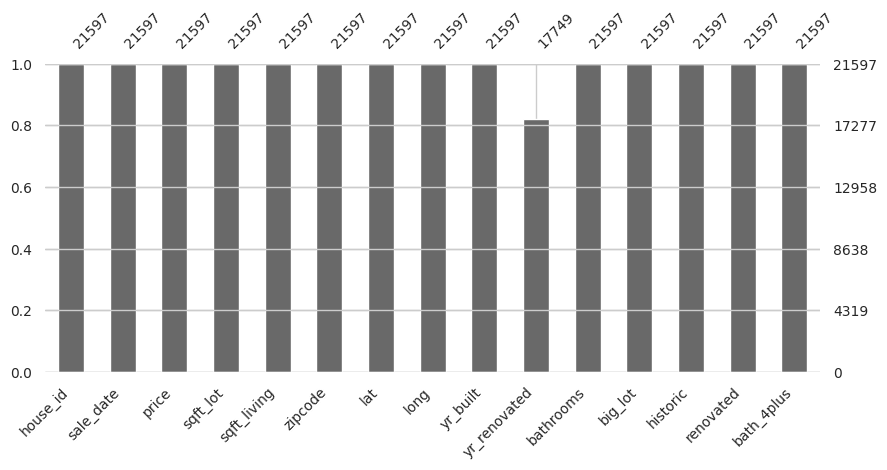

yr_renovated    3848
dtype: int64

In [6]:
msno.bar(df, figsize=(10, 4), fontsize=10)
plt.show()
df.isna().sum()[df.isna().sum() > 0]

Nur `yr_renovated` hat fehlende Werte (ca. 3.800, also rund 18 %). Alle anderen Spalten sind vollständig. Da im Datensatz „nicht renoviert“ meist als 0 codiert ist, ist ein fehlender Wert sehr wahrscheinlich ebenfalls „nicht renoviert“ (oder unbekannt). Wir behandeln ihn deshalb als 0.

### 3.3 Kontinuierliche vs. kategoriale Features

- **Kontinuierlich:** `price`, `sqft_lot`, `sqft_living`, `lat`, `long`
- **Diskret / ordinal:** `bathrooms` (in Viertelschritten), `yr_built`, `yr_renovated`
- **Kategorial:** `zipcode`, `big_lot`, `historic`, `renovated`, `bath_4plus`

`zipcode` ist zwar eine Zahl, aber inhaltlich eine Kategorie: Mit Postleitzahlen zu rechnen ergibt keinen Sinn.

## 4. Daten explorieren

### 4.1 Verteilungen der kontinuierlichen Variablen

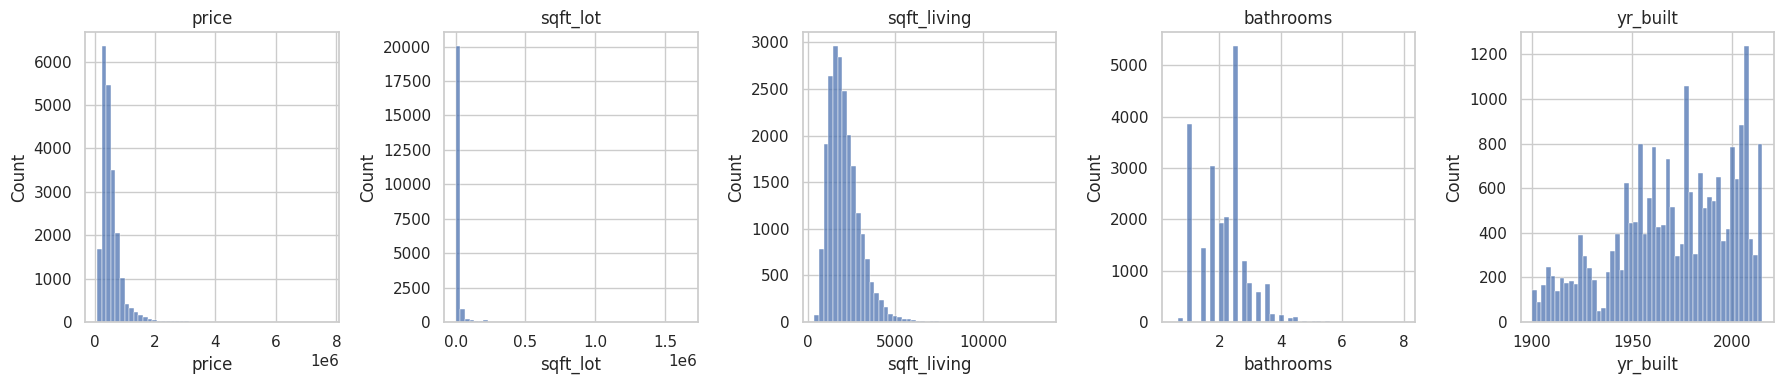

In [7]:
cont_cols = ["price", "sqft_lot", "sqft_living", "bathrooms", "yr_built"]
fig, axes = plt.subplots(1, len(cont_cols), figsize=(18, 4))
for ax, col in zip(axes, cont_cols):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

`price`, `sqft_lot` und `sqft_living` sind stark rechtsschief, bei `sqft_lot` sieht man fast nur einen Balken ganz links. Für Vergleiche und Korrelationen nutzen wir daher Log-Skalen bzw. die Spearman-Korrelation, die robust gegenüber Schiefe ist. `bathrooms` konzentriert sich zwischen 1 und 3,5, und `yr_built` zeigt einen Bauboom ab den 1950ern sowie einen zweiten in den 2000ern.

### 4.2 Verteilungen der kategorialen Variablen

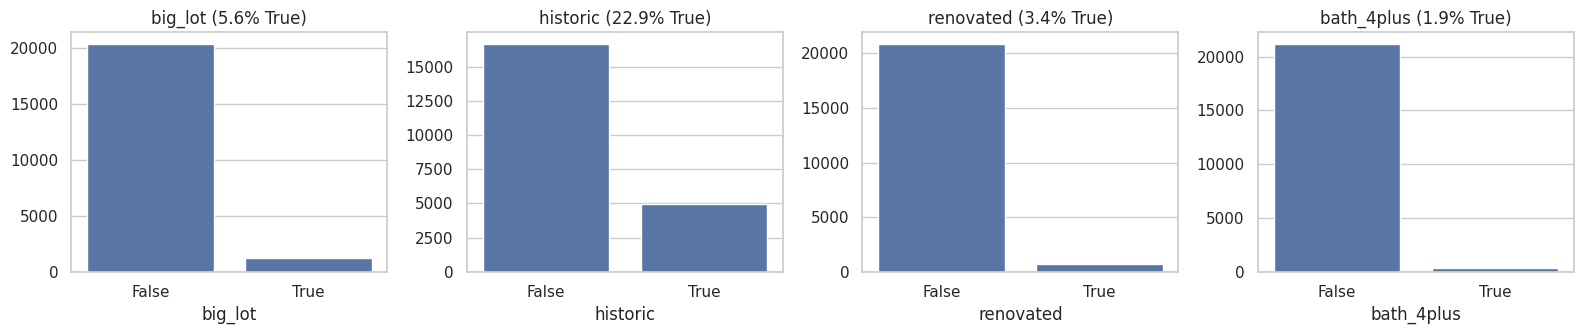

In [8]:
flag_cols = ["big_lot", "historic", "renovated", "bath_4plus"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, flag_cols):
    counts = df[col].value_counts()
    sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax)
    ax.set_title(f"{col} ({df[col].mean():.1%} True)")
plt.tight_layout()
plt.show()

Die für den Kunden relevanten Merkmale sind selten: Nur rund 6 % der Verkäufe haben ein großes Grundstück, knapp 2 % haben 4+ Badezimmer und nur 3–4 % wurden je renoviert. Historisch (vor 1950) sind dagegen fast ein Viertel der Häuser. Schon hier zeichnet sich ab, dass die Schnittmenge aller Wünsche klein sein wird.

## 5. Daten bereinigen

### 5.1 `yr_renovated` korrigieren

Die gültigen Werte liegen zwischen 19.340 und 20.150, also wurde das Jahr offenbar mit dem Faktor 10 gespeichert. Wir teilen durch 10 und setzen fehlende Werte auf 0.

In [9]:
print("Vorher:", sorted(df.loc[df["yr_renovated"] > 0, "yr_renovated"].unique())[:5])

df["yr_renovated"] = (df["yr_renovated"].fillna(0) / 10).astype(int)
df["renovated"] = df["yr_renovated"] > 0

print("Nachher:", sorted(df.loc[df["yr_renovated"] > 0, "yr_renovated"].unique())[:5])
print(f"Renovierte Häuser: {df['renovated'].sum():,}")

Vorher: [np.float64(19340.0), np.float64(19400.0), np.float64(19440.0), np.float64(19450.0), np.float64(19460.0)]
Nachher: [np.int64(1934), np.int64(1940), np.int64(1944), np.int64(1945), np.int64(1946)]
Renovierte Häuser: 744


Jetzt stehen dort echte Jahreszahlen (z. B. 1934, 1940 …). Das Flag `renovated` bleibt inhaltlich gleich, wird aber zur Sicherheit neu berechnet.

### 5.2 Duplikate

Manche Häuser wurden im Zeitraum mehrfach verkauft. Für unsere Hypothesen interessieren uns **Häuser**, nicht Transaktionen. Würden wir alle Zeilen behalten, zählten mehrfach verkaufte Häuser doppelt. Wir behalten deshalb pro Haus den **letzten** Verkauf, weil er den aktuellsten Marktpreis widerspiegelt.

In [10]:
n_before = len(df)
print(f"Zeilen mit mehrfach verkauften Häusern: {df['house_id'].duplicated(keep=False).sum()}")

df = df.sort_values("sale_date").drop_duplicates("house_id", keep="last")
print(f"Entfernt: {n_before - len(df)} Zeilen | Verbleibend: {len(df):,}")

Zeilen mit mehrfach verkauften Häusern: 353
Entfernt: 177 Zeilen | Verbleibend: 21,420


### 5.3 Ausreißer

Wir entfernen hier bewusst **keine** Ausreißer, und zwar aus inhaltlichen Gründen:

- **Sehr große Grundstücke** sind genau das, was der Kunde sucht. Sie zu entfernen, würde die relevantesten Objekte löschen.
- **Sehr teure Häuser** sind bei einem unbegrenzten Budget ebenfalls relevant.
- Die Werte sind plausibel (es gibt in King County ländliche Grundstücke mit 30+ Acres), es handelt sich also nicht um Messfehler.

Stattdessen gehen wir mit der Schiefe über Log-Transformation und robuste Kennzahlen (Median, Spearman) um. Ein kurzer Plausibilitätscheck:

In [11]:
df[["price", "sqft_lot", "sqft_living", "bathrooms"]].describe(percentiles=[0.5, 0.95, 0.99]).T

,count,mean,std,min,50%,95%,99%,max
price,21420.000,541861.428,367556.938,78000.000,450550.000,1160000.000,1970000.000,7700000.000
sqft_lot,21420.000,15128.038,41530.797,520.000,7614.000,43560.000,213008.000,1651359.000
sqft_living,21420.000,2083.133,918.808,370.000,1920.000,3770.000,4980.000,13540.000
bathrooms,21420.000,2.118,0.769,0.500,2.250,3.500,4.250,8.000


Selbst das 99. Perzentil von `sqft_lot` liegt bei rund 210.000 sqft (knapp 5 Acres), das ist für ländliche Gegenden realistisch.

### 5.4 Neues Feature: Distanz zum Stadtzentrum

Für H1 brauchen wir eine messbare Größe für „außerhalb des Zentrums“. Aus `lat`/`long` berechnen wir mit der Haversine-Formel die Luftlinie zu Downtown Seattle in Kilometern und teilen sie in Distanzklassen ein.

In [12]:
SEATTLE_CENTER = (47.6062, -122.3321)


def haversine_km(lat, lon, lat0=SEATTLE_CENTER[0], lon0=SEATTLE_CENTER[1]):
    """Luftlinie in km zwischen (lat, lon) und einem Referenzpunkt."""
    r = 6371
    lat, lon, lat0, lon0 = map(np.radians, [lat, lon, lat0, lon0])
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat) * np.sin((lon - lon0) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


df["dist_km"] = haversine_km(df["lat"], df["long"])
df["dist_bin"] = pd.cut(
    df["dist_km"], bins=[0, 10, 20, 30, 40, 100], labels=["0–10", "10–20", "20–30", "30–40", "40+"]
)
df["dist_km"].describe()

count   21420.000
mean       18.455
std        10.648
min         0.983
25%         9.774
50%        16.510
75%        25.271
max        77.094
Name: dist_km, dtype: float64

### 5.5 Wie viele Daten haben wir verloren?

In [13]:
n_raw = 21597
print(f"Ausgangsdaten: {n_raw:,} | Nach Cleaning: {len(df):,} | Verlust: {(n_raw - len(df)) / n_raw:.1%}")

Ausgangsdaten: 21,597 | Nach Cleaning: 21,420 | Verlust: 0.8%


Wir haben nur rund 0,8 % der Zeilen entfernt, und zwar ausschließlich Duplikate. Die Analyse basiert also auf nahezu dem vollständigen Datensatz.

## 6. Hypothese 1: Große Grundstücke liegen eher außerhalb der Stadtzentren

### 6.1 Geografischer Überblick

Eine Karte aus `lat`/`long` zeigt, wo die großen Grundstücke liegen. Der rote Stern markiert Downtown Seattle.

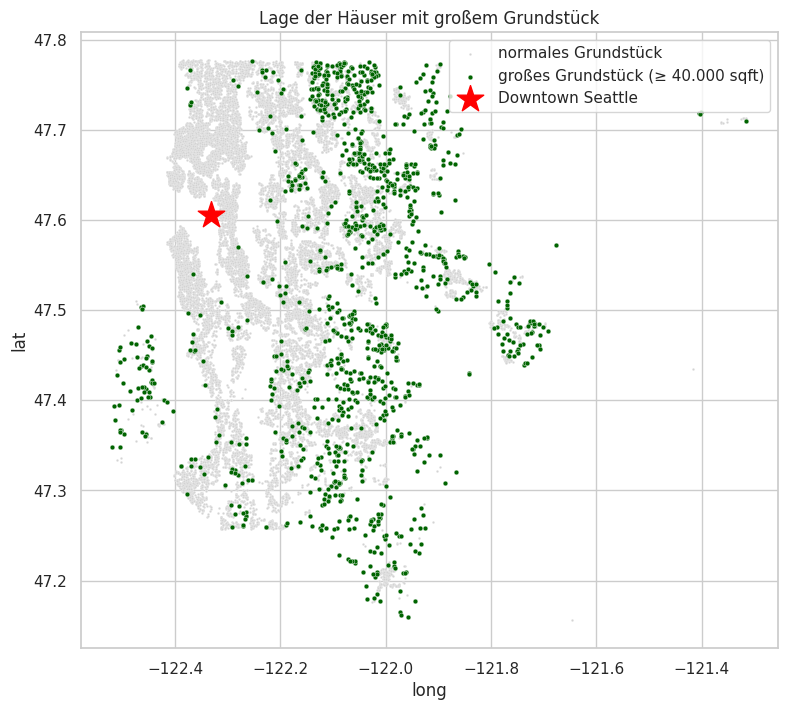

In [14]:
fig, ax = plt.subplots(figsize=(9, 8))
sns.scatterplot(data=df[~df["big_lot"]], x="long", y="lat", s=3, color="lightgrey", label="normales Grundstück", ax=ax)
sns.scatterplot(data=df[df["big_lot"]], x="long", y="lat", s=12, color="darkgreen", label="großes Grundstück (≥ 40.000 sqft)", ax=ax)
ax.scatter(SEATTLE_CENTER[1], SEATTLE_CENTER[0], marker="*", s=400, color="red", label="Downtown Seattle")
ax.set_title("Lage der Häuser mit großem Grundstück")
ax.legend(loc="upper right")
plt.show()

Die großen Grundstücke (grün) fehlen im Stadtgebiet von Seattle fast vollständig. Sie bündeln sich am Rand im Osten (Woodinville, Redmond, Sammamish, Issaquah), im Südosten (Maple Valley, Enumclaw) und auf Vashon Island im Westen.

### 6.2 Grundstücksgröße nach Distanzklasse

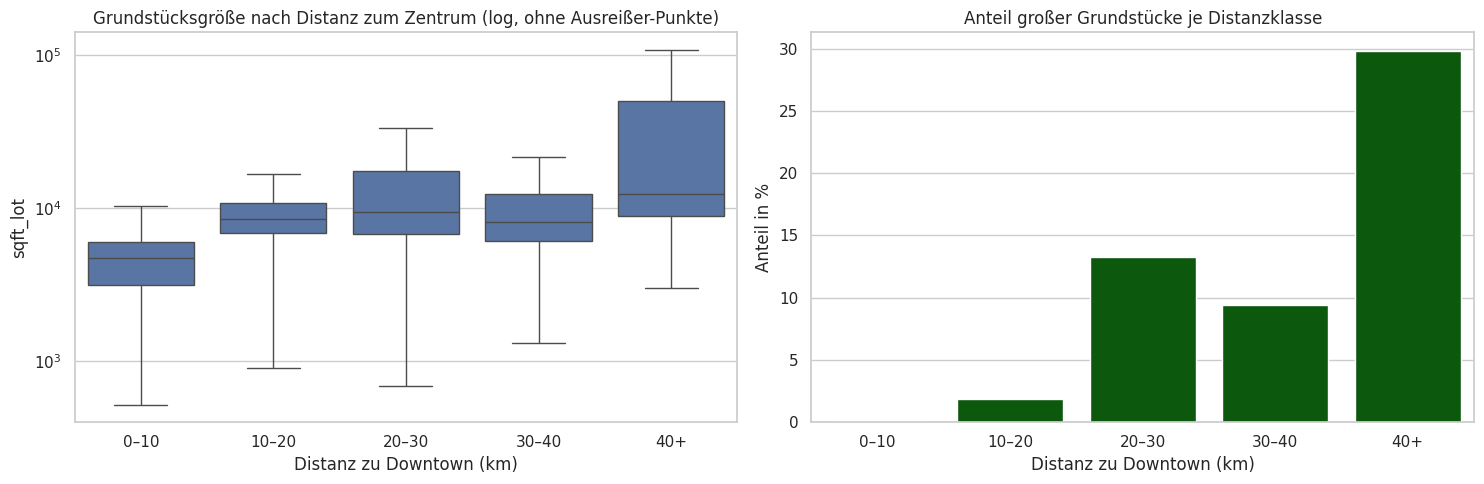

,anzahl,median_lot,anteil_big_lot,median_preis
dist_bin,,,,
0–10,5580,4725.000,0.001,559000.000
10–20,7685,8400.000,0.019,455000.000
20–30,4418,9328.000,0.133,460000.000
30–40,3187,8125.000,0.094,306000.000
40+,550,12234.500,0.298,325000.000


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df, x="dist_bin", y="sqft_lot", showfliers=False, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Grundstücksgröße nach Distanz zum Zentrum (log, ohne Ausreißer-Punkte)")
axes[0].set_xlabel("Distanz zu Downtown (km)")

share = df.groupby("dist_bin", observed=True)["big_lot"].mean() * 100
sns.barplot(x=share.index.astype(str), y=share.values, color="darkgreen", ax=axes[1])
axes[1].set_title("Anteil großer Grundstücke je Distanzklasse")
axes[1].set_xlabel("Distanz zu Downtown (km)")
axes[1].set_ylabel("Anteil in %")
plt.tight_layout()
plt.show()

df.groupby("dist_bin", observed=True).agg(
    anzahl=("price", "size"),
    median_lot=("sqft_lot", "median"),
    anteil_big_lot=("big_lot", "mean"),
    median_preis=("price", "median"),
)

Im Umkreis von 10 km um Downtown ist praktisch kein großes Grundstück zu finden (unter 0,1 %). Ab 20 km steigt der Anteil sprunghaft auf über 13 %, jenseits von 40 km hat fast jedes dritte Haus ein großes Grundstück. Der Median der Grundstücksgröße verdoppelt sich von rund 4.700 sqft im Zentrum auf über 9.000 sqft in 20–30 km Entfernung. Der kleine Rückgang bei 30–40 km liegt an dichter bebauten Vororten im Süden (z. B. Kent, Auburn).

### 6.3 Statistischer Test

In [16]:
rho, p = stats.spearmanr(df["dist_km"], df["sqft_lot"])
print(f"Spearman ρ (Distanz vs. Grundstücksgröße): {rho:.2f}, p = {p:.1e}")
print(df.groupby("big_lot")["dist_km"].median().rename("Median-Distanz (km)"))

Spearman ρ (Distanz vs. Grundstücksgröße): 0.44, p = 0.0e+00
big_lot
False   15.979
True    28.047
Name: Median-Distanz (km), dtype: float64


Mit ρ ≈ 0,44 besteht ein deutlicher positiver Zusammenhang. Große Grundstücke liegen im Median rund 28 km vom Zentrum entfernt, normale nur rund 16 km.

**Ergebnis H1: bestätigt.** Je weiter vom Zentrum entfernt, desto größer das Grundstück.

## 7. Hypothese 2: Historische Häuser haben im Schnitt weniger Badezimmer als neuere Häuser

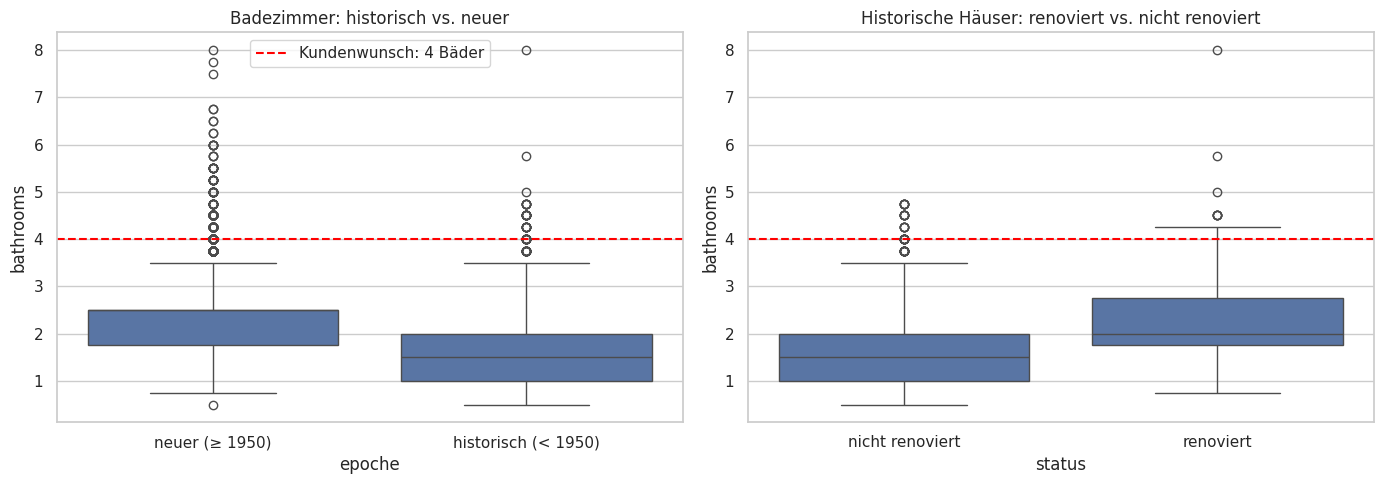

In [17]:
df["epoche"] = np.where(df["historic"], "historisch (< 1950)", "neuer (≥ 1950)")
hist = df[df["historic"]].copy()
hist["status"] = np.where(hist["renovated"], "renoviert", "nicht renoviert")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="epoche", y="bathrooms", ax=axes[0])
axes[0].axhline(4, ls="--", color="red", label="Kundenwunsch: 4 Bäder")
axes[0].set_title("Badezimmer: historisch vs. neuer")
axes[0].legend()

sns.boxplot(data=hist, x="status", y="bathrooms", order=["nicht renoviert", "renoviert"], ax=axes[1])
axes[1].axhline(4, ls="--", color="red")
axes[1].set_title("Historische Häuser: renoviert vs. nicht renoviert")
plt.tight_layout()
plt.show()

Historische Häuser haben im Median 1,5 Badezimmer, neuere 2,5. Innerhalb der historischen Häuser verschiebt eine Renovierung die Verteilung deutlich nach oben (Median von 1,5 auf 2). Die rote Linie zeigt: 4+ Bäder sind in beiden historischen Gruppen die absolute Ausnahme.

In [18]:
summary = pd.concat([
    df.groupby("epoche")[["bathrooms", "bath_4plus"]].agg(["median", "mean"]),
    hist.groupby("status")[["bathrooms", "bath_4plus"]].agg(["median", "mean"]),
])
summary

bathrooms       bath_4plus      
                       median  mean     median  mean
historisch (< 1950)     1.500 1.629      0.000 0.010
neuer (≥ 1950)          2.500 2.263      0.000 0.021
nicht renoviert         1.500 1.567      0.000 0.007
renoviert               2.000 2.216      0.000 0.039

In [19]:
u1, p1 = stats.mannwhitneyu(df.loc[df["historic"], "bathrooms"], df.loc[~df["historic"], "bathrooms"])
u2, p2 = stats.mannwhitneyu(hist.loc[hist["renovated"], "bathrooms"], hist.loc[~hist["renovated"], "bathrooms"])
print(f"Historisch vs. neuer:              p = {p1:.1e}")
print(f"Historisch renoviert vs. nicht:    p = {p2:.1e}")

Historisch vs. neuer:              p = 0.0e+00
Historisch renoviert vs. nicht:    p = 1.7e-62


Wir nutzen den Mann-Whitney-U-Test, weil `bathrooms` diskret und nicht normalverteilt ist. Beide Unterschiede sind hochsignifikant. Besonders relevant für den Kunden ist der Anteil mit 4+ Bädern: Bei nicht renovierten historischen Häusern liegt er unter 1 %, bei renovierten bei knapp 4 %, also mehr als fünfmal so hoch.

**Ergebnis H2: bestätigt.** Historische Häuser haben im Schnitt weniger Badezimmer als neuere (Median 1,5 gegenüber 2,5). Ergänzend holen renovierte historische Häuser deutlich auf.

## 8. Hypothese 3: Je größer das Grundstück, desto höher der Preis, aber der Zusammenhang ist schwächer als bei der Wohnfläche

### 8.1 Korrelationsmatrix

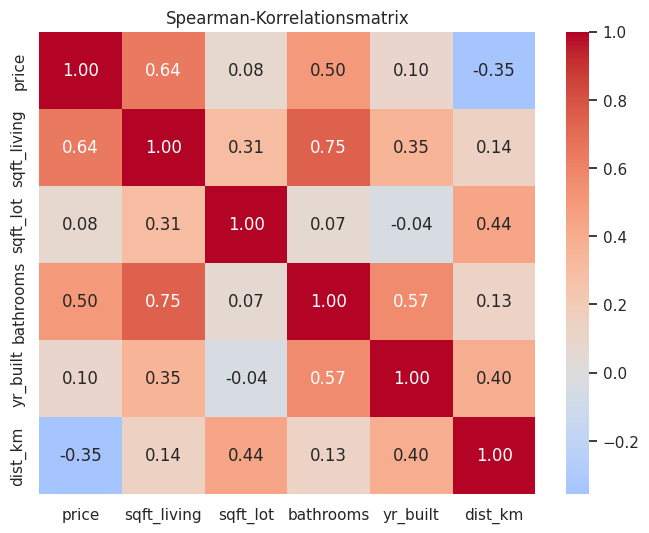

In [20]:
corr_cols = ["price", "sqft_living", "sqft_lot", "bathrooms", "yr_built", "dist_km"]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman-Korrelationsmatrix")
plt.show()

Die Wohnfläche korreliert mit ρ ≈ 0,64 stark mit dem Preis, die Grundstücksgröße dagegen kaum (ρ ≈ 0,08). Nebenbei sieht man: Die Distanz zum Zentrum korreliert negativ mit dem Preis, und Bäder hängen stark mit der Wohnfläche zusammen.

### 8.2 Streudiagramme auf Log-Skala

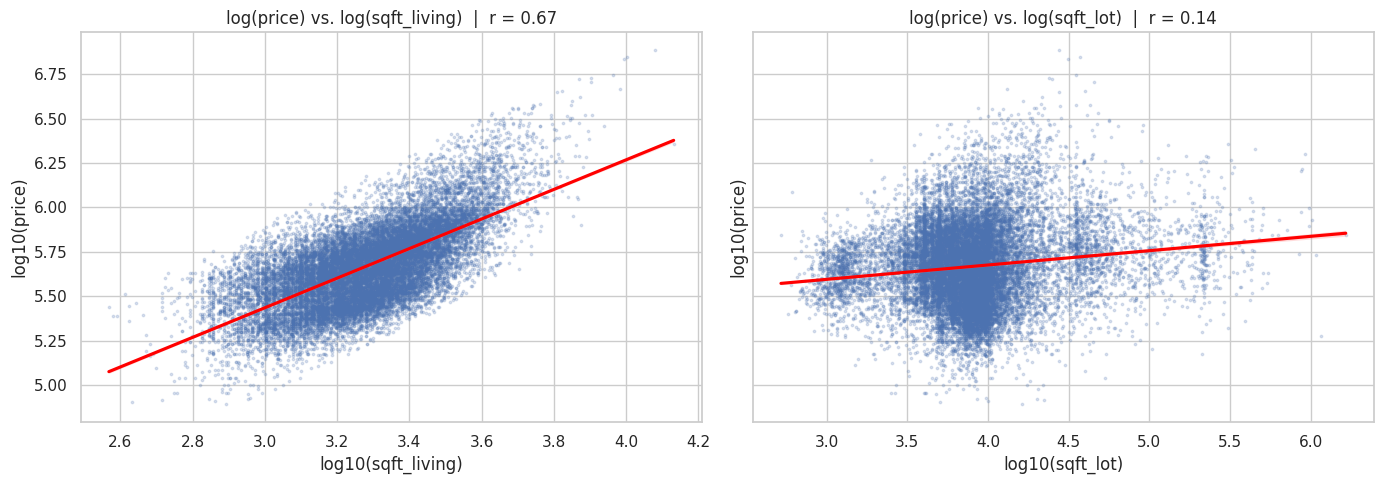

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, col in zip(axes, ["sqft_living", "sqft_lot"]):
    sns.regplot(
        x=np.log10(df[col]), y=np.log10(df["price"]), ax=ax,
        scatter_kws={"s": 3, "alpha": 0.2}, line_kws={"color": "red"},
    )
    r = np.corrcoef(np.log(df[col]), np.log(df["price"]))[0, 1]
    ax.set_title(f"log(price) vs. log({col})  |  r = {r:.2f}")
    ax.set_xlabel(f"log10({col})")
    ax.set_ylabel("log10(price)")
plt.tight_layout()
plt.show()

Links eine klare, fast lineare Punktwolke: Mehr Wohnfläche bedeutet einen höheren Preis. Rechts ist die Wolke nahezu flach. Auch auf Log-Skala erklärt die Grundstücksgröße den Preis kaum.

### 8.3 Was kostet ein Quadratfuß Grundstück?

Wenn das Grundstück wenig zum Preis beiträgt, sollte große Fläche pro sqft günstig sein. Das prüfen wir mit dem Preis pro sqft Grundstück.

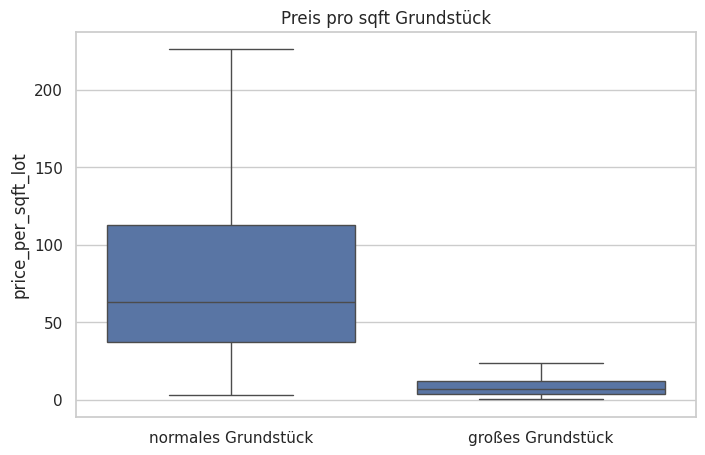

big_lot
False   63.183
True     7.124
Name: price_per_sqft_lot, dtype: float64

In [22]:
df["price_per_sqft_lot"] = df["price"] / df["sqft_lot"]
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="big_lot", y="price_per_sqft_lot", showfliers=False, ax=ax)
ax.set_xticklabels(["normales Grundstück", "großes Grundstück"])
ax.set_xlabel("")
ax.set_title("Preis pro sqft Grundstück")
plt.show()
df.groupby("big_lot")["price_per_sqft_lot"].median()

Bei großen Grundstücken kostet ein sqft Land im Median rund 7 $, bei normalen rund 63 $, also fast neunmal so viel. Große Grundstücke liegen weit draußen, wo Land günstig ist (siehe H1).

**Ergebnis H3: bestätigt.** Zwischen Grundstücksgröße und Preis besteht ein positiver, aber sehr schwacher Zusammenhang (ρ ≈ 0,08), deutlich schwächer als bei der Wohnfläche (ρ ≈ 0,64).

## 9. Was bedeutet das für Jacob Phillips?

Wir kombinieren die Kriterien aus H1 und H2: großes Grundstück **und** historisch.

In [23]:
candidates = df[df["big_lot"] & df["historic"]]
print(f"Großes Grundstück:                          {df['big_lot'].sum():>5}")
print(f"Großes Grundstück + historisch:             {len(candidates):>5}")
print(f"Großes Grundstück + historisch + 4+ Bäder:  {candidates['bath_4plus'].sum():>5}")
print(f"Davon renoviert:                            {candidates['renovated'].sum():>5}")

Großes Grundstück:                           1202
Großes Grundstück + historisch:               119
Großes Grundstück + historisch + 4+ Bäder:      3
Davon renoviert:                               22


Die Schnittmenge ist winzig: Nur rund 120 historische Häuser haben ein großes Grundstück, und davon haben gerade einmal 3 bereits 4+ Badezimmer. Die Anforderung „4+ Bäder“ ist also der Engpass, nicht das Grundstück.

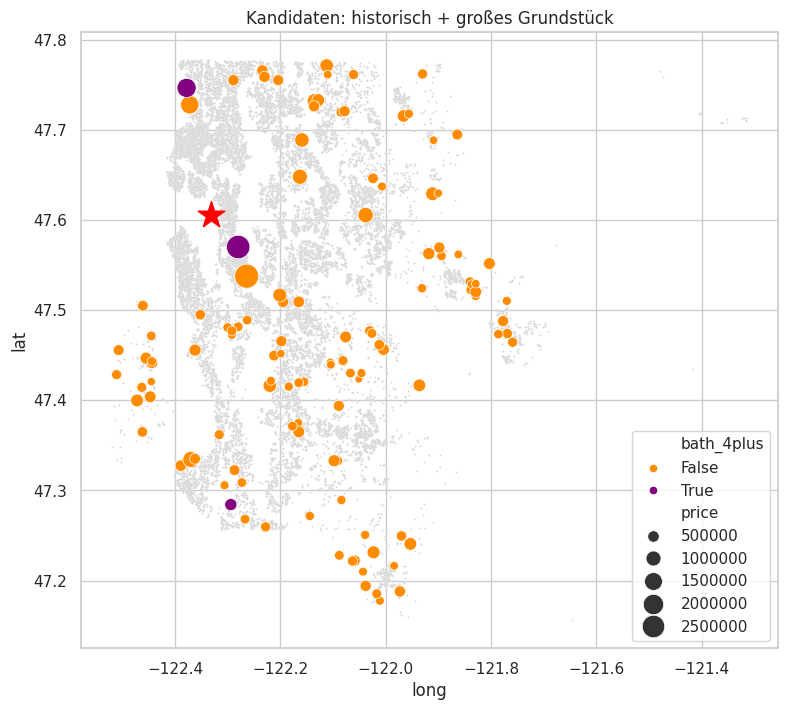

,anzahl,median_preis,median_lot,median_dist_km
zipcode,,,,
98022,13,349990.000,223462.000,49.144
98070,12,398592.500,56172.500,21.777
98065,7,300000.000,90169.000,38.697
98042,6,303000.000,58020.500,29.091
98024,5,275000.000,102366.000,32.808
98058,5,299950.000,77603.000,26.076
98045,5,356000.000,48693.000,43.683
98072,4,720000.000,78555.500,22.402
98092,4,290250.000,79455.000,39.588


In [24]:
fig, ax = plt.subplots(figsize=(9, 8))
sns.scatterplot(data=df, x="long", y="lat", s=2, color="lightgrey", ax=ax)
sns.scatterplot(
    data=candidates, x="long", y="lat", hue="bath_4plus", size="price",
    sizes=(30, 300), palette={False: "darkorange", True: "purple"}, ax=ax,
)
ax.scatter(SEATTLE_CENTER[1], SEATTLE_CENTER[0], marker="*", s=400, color="red")
ax.set_title("Kandidaten: historisch + großes Grundstück")
plt.show()

top_zip = candidates.groupby("zipcode").agg(
    anzahl=("price", "size"), median_preis=("price", "median"),
    median_lot=("sqft_lot", "median"), median_dist_km=("dist_km", "median"),
).sort_values("anzahl", ascending=False)
top_zip.head(10)

Die Kandidaten sind breit über das County verteilt. Häufungen gibt es im Südosten um Enumclaw (98022), auf Vashon Island (98070) und um Snoqualmie (98065), wo die Grundstücke im Median sehr groß und die Preise moderat sind. Interessant: Die beiden teuersten Kandidaten liegen nur 5–10 km von Downtown entfernt. Große historische Grundstücke in Stadtnähe gibt es also, sie sind aber extrem selten und entsprechend teuer. Zwei der drei Häuser mit 4+ Bädern (lila) liegen ebenfalls nah an Seattle.

*Achtung:* Vashon Island ist eine Insel. Dort ist das Risiko hoch, dass Objekte eine Wasserlage haben, was der Kunde ausschließt. `waterfront` sollte vor einer Besichtigung geprüft werden.

In [25]:
candidates.sort_values("price", ascending=False)[
    ["zipcode", "price", "sqft_lot", "sqft_living", "bathrooms", "yr_built", "renovated", "dist_km"]
].head(10)

,zipcode,price,sqft_lot,sqft_living,bathrooms,yr_built,renovated,dist_km
6396,98118,2900000.000,91681.000,3750.000,2.500,1925,False,9.153
5961,98144,2730000.000,43838.000,6410.000,4.250,1906,False,5.586
15152,98177,1760000.000,67953.000,3860.000,4.000,1927,False,16.018
11717,98177,1580000.000,74487.000,4570.000,2.500,1948,True,13.891
4365,98023,1150000.000,75889.000,3230.000,2.750,1925,True,30.357
13405,98072,1140000.000,127631.000,3310.000,2.250,1924,True,20.389
18670,98074,1050000.000,44431.000,1860.000,1.000,1947,False,22.049
3546,98005,1010000.000,41339.000,2240.000,2.500,1945,True,13.509
358,98033,900000.000,77972.000,1330.000,1.000,1928,True,15.910
14771,98056,825000.000,42247.000,1240.000,1.000,1915,False,13.977


## 10. Insights

1. **Geografisch:** Große Grundstücke gibt es fast nur außerhalb von Seattle. Im 10-km-Radius um Downtown liegt der Anteil unter 0,1 %, ab 20 km bei über 13 %. Schwerpunkte sind der Osten (z. B. 98053 Redmond, 98077 Woodinville, 98027 Issaquah) und Vashon Island.
2. **Historische Häuser sind bei den Bädern im Nachteil:** Sie haben im Median nur 1,5 Bäder; 4+ Bäder sind selten. Renovierte historische Häuser haben deutlich mehr Bäder.
3. **Grundstück ist billig, Wohnfläche ist teuer:** Der Preis hängt vor allem an der Wohnfläche. Ein sqft Land kostet bei großen Grundstücken nur ein Neuntel dessen, was es bei normalen kostet.

## 11. Empfehlungen für Jacob Phillips

1. **Suche auf das Umland konzentrieren** (20+ km von Downtown), vor allem auf den Osten und Südosten (z. B. 98022 Enumclaw, 98065 Snoqualmie, 98072 Woodinville). Nur dort gibt es nennenswert viele historische Häuser mit Platz für Tennisplatz und Pool. Wer unbedingt stadtnah wohnen will, findet einzelne Ausnahmen in Seattle (98118, 98144, 98177), muss dann aber mit 1,7–2,9 Mio. $ rechnen.
2. **Nicht auf 4+ Bäder bestehen, sondern umbauen oder erweitern:** Historische Häuser mit großem Grundstück und 4+ Bädern gibt es praktisch nicht (3 Objekte). Besser ein historisches Haus auf großem Grundstück kaufen und Bäder ergänzen oder ein Gästehaus auf dem Grundstück bauen. Das erfüllt auch den Wunsch nach einem „kleineren Haus in der Nähe“, und der Platz dafür ist vorhanden.
3. **Budget in Haus und Ausstattung statt in Grundstücksfläche investieren:** Zusätzliche Fläche ist draußen günstig. Mit unbegrenztem Budget lohnt es sich, eher das schönste historische Haus mit großem Grundstück zu wählen und in Renovierung, Tennisplatz und Pool zu investieren, als einen Aufpreis für noch mehr Land zu zahlen.

**Nächste Schritte:** Golfplatz-Koordinaten (z. B. aus OpenStreetMap) ergänzen und die Kandidaten nach Distanz zum nächsten Golfplatz filtern; Wasserlage (`waterfront`) aus der Datenbank nachladen, um Objekte mit Wasserlage auszuschließen.